# Exploratory Data Analysis — Sentiment140

**Study context.** This notebook profiles the *Sentiment140* corpus (1.6M distant-supervised English tweets) in direct support of a **dual-path adaptive hybrid** sentiment classifier: an interpretable **semantic** expert (a Concept-Bottleneck KAN over fine-tuned DeBERTa embeddings) and a **structural** expert (XGBoost over engineered linguistic features). The EDA is therefore organised not only around generic text statistics but around the study's central premise — that sentiment is carried through **two complementary channels, semantic meaning and structural form** — and every finding is tied back to a modelling implication.

**Corpus caveat, stated up front.** Sentiment140 labels are *distant-supervised*: polarity was inferred automatically from emoticons at collection time, not by human annotation. The EDA explicitly quantifies the consequences of this (label noise, an accuracy ceiling, sarcasm-driven mislabels) rather than treating the labels as gold.

**Sections**
1. Data loading & configuration  2. Dataset overview & class balance  3. Data-quality assessment  4. Tweet-length distribution  5. Vocabulary & token analysis  6. Word & n-gram frequency  7. Hashtags & mentions  8. Emoji, emoticon & punctuation  9. Structural-feature analysis (the structural channel)  10. Structural-only separability (motivating the dual path)  11. Label quality & distant-supervision noise  12. Negation & sarcasm deep-dive (motivating the semantic KAN)  13. Findings & modelling implications


## 1. Data loading & configuration

In [1]:
import os, re, warnings, math
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
PALETTE = {0: "#eb6834", 1: "#1baf7a"}   # 0 = negative, 1 = positive
LAB = {0: "negative", 1: "positive"}

# --- configuration --------------------------------------------------------
from pathlib import Path
def _find_root(start=None):
    # Locate the project root (folder containing data/splitsfull) so the
    # notebook runs whether launched from the repo root or from notebooks/.
    p = Path(start or Path.cwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "data" / "splitsfull" / "train.csv").exists():
            return cand
    return p
PROJECT_ROOT = _find_root()
DATA_DIR   = str(PROJECT_ROOT / "data" / "splitsfull")   # full Sentiment140 splits
LOAD_ROWS  = None                    # None = load the full train split
SAMPLE     = 150_000                 # subsample size for heavy text operations
SEED       = 42
FIG_DIR    = str(PROJECT_ROOT / "outputs" / "eda"); os.makedirs(FIG_DIR, exist_ok=True)
print("Project root:", PROJECT_ROOT)

def savefig(name):
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")


Project root: C:\Users\User\Documents\kan_xgboost_sentiment


In [2]:
# Load splits (train is the analysis focus; val/test only for the size table)
train = pd.read_csv(f"{DATA_DIR}/train.csv", nrows=LOAD_ROWS)
sizes = {s: sum(1 for _ in open(f"{DATA_DIR}/{s}.csv", encoding="utf-8")) - 1
         for s in ("train", "val", "test")}
print("Split sizes:", sizes)
print(f"Loaded train rows: {len(train):,} | columns: {len(train.columns)}")

# Text + structural feature columns
TEXT_COLS = ["text", "clean_text", "hashtag_text", "emoticon_text"]
STRUCT = [c for c in train.columns if c not in TEXT_COLS + ["label"]]
train["text"] = train["text"].fillna("").astype(str)
train["clean_text"] = train["clean_text"].fillna("").astype(str)

# reproducible sample for token/word/emoji work
samp = train.sample(min(SAMPLE, len(train)), random_state=SEED).reset_index(drop=True)
print(f"Heavy-op sample: {len(samp):,} tweets")
STRUCT


Split sizes: {'train': 1280000, 'val': 160000, 'test': 160000}
Loaded train rows: 1,280,000 | columns: 38


Heavy-op sample: 150,000 tweets


['neg_count',
 'neg_ratio',
 'intensifier_count',
 'intensifier_ratio',
 'elongated_word_count',
 'emoticon_count',
 'punct_count',
 'punct_density',
 'exclaim_count',
 'question_count',
 'ellipsis_count',
 'interrobang_count',
 'caps_ratio',
 'allcaps_word_count',
 'allcaps_word_ratio',
 'sarcasm_cue_count',
 'sarcasm_flag',
 'subjectivity',
 'hashtag_count',
 'hashtag_sentiment',
 'hashtag_pos_count',
 'hashtag_neg_count',
 'pos_adj_ratio',
 'pos_adv_ratio',
 'pos_verb_ratio',
 'pos_noun_ratio',
 'pos_pron_ratio',
 'pos_intj_ratio',
 'dep_neg_count',
 'dep_amod_count',
 'dep_advmod_count',
 'dep_max_depth',
 'dep_mean_depth']

## 2. Dataset overview & class balance
Sentiment140 is balanced by construction, which makes plain **accuracy** a meaningful headline metric and removes the need for class re-balancing in the semantic path.

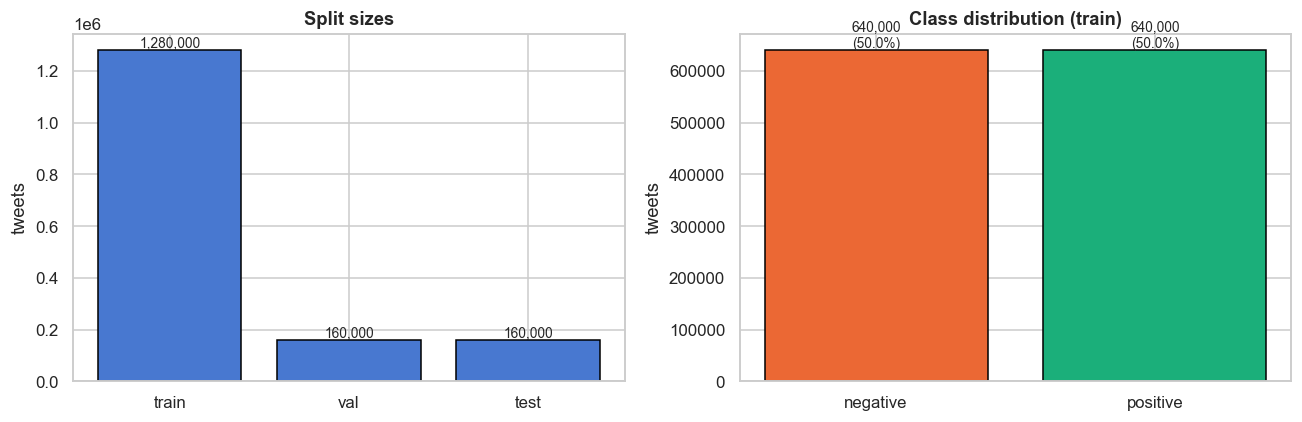

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# split sizes
ax[0].bar(sizes.keys(), sizes.values(), color="#4878d0", edgecolor="black")
ax[0].set_title("Split sizes"); ax[0].set_ylabel("tweets")
for i, (k, v) in enumerate(sizes.items()):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
# class balance (train)
vc = train["label"].value_counts().sort_index()
ax[1].bar([LAB[i] for i in vc.index], vc.values, color=[PALETTE[i] for i in vc.index], edgecolor="black")
ax[1].set_title("Class distribution (train)"); ax[1].set_ylabel("tweets")
for i, v in enumerate(vc.values):
    ax[1].text(i, v, f"{v:,}\n({v/len(train):.1%})", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); savefig("01_overview"); plt.show()


In [4]:
# A few example tweets per class
for c in (1, 0):
    print(f"\n===== {LAB[c].upper()} examples =====")
    for t in train.loc[train.label == c, "text"].head(4):
        print(" •", t[:120])



===== POSITIVE examples =====
 • - going somewhat out of town? (x visitng uncle boyet &amp; famm! 
 • reevaluating, rethinking, restructuring.. get it 
 • @sweetjamielee and you have some fic rec? wanna help writing? need a beta? wanna beta one? 
 • @xxpinkbabesx  Even though she still has not apologized! Thats all im looking foward to

===== NEGATIVE examples =====
 • @briancag aw why?  orrrrrrr is that a good thing..
 • @TheGlamSpot  I will see what I can do, a bit wind blown now 
 • @dvl5663 poor Lil' D   At least u can still tweet
 • its too hot. also the strangers is a really scary movie 


## 3. Data-quality assessment
Missingness, exact duplicates, and empty post-cleaning text are checked because they affect both experts (empty text yields degenerate embeddings and all-zero feature rows).

In [5]:
quality = {
    "rows": len(train),
    "missing_text": int((train['text'].str.strip() == '').sum()),
    "missing_clean_text": int((train['clean_text'].str.strip() == '').sum()),
    "exact_duplicate_text": int(train['text'].duplicated().sum()),
    "duplicate_clean_text": int(train['clean_text'].duplicated().sum()),
    "null_label": int(train['label'].isna().sum()),
}
qdf = pd.DataFrame.from_dict(quality, orient='index', columns=['count'])
qdf['pct'] = (qdf['count'] / len(train) * 100).round(3)
display(qdf)
# duplicates are worth watching: retweets/quotes inflate frequent phrases
print("Structural columns with any NaN:",
      [c for c in STRUCT if train[c].isna().any()] or "none")


,count,pct
rows,1280000,100.000
missing_text,0,0.000
missing_clean_text,0,0.000
exact_duplicate_text,13464,1.052
duplicate_clean_text,52179,4.076
null_label,0,0.000


Structural columns with any NaN: none


## 4. Tweet-length distribution (§3.3.1)
Length drives two design choices: the embedding **max-token length** (semantic path) and length-normalised ratios in the feature set (structural path). We inspect character and word length overall and per class.

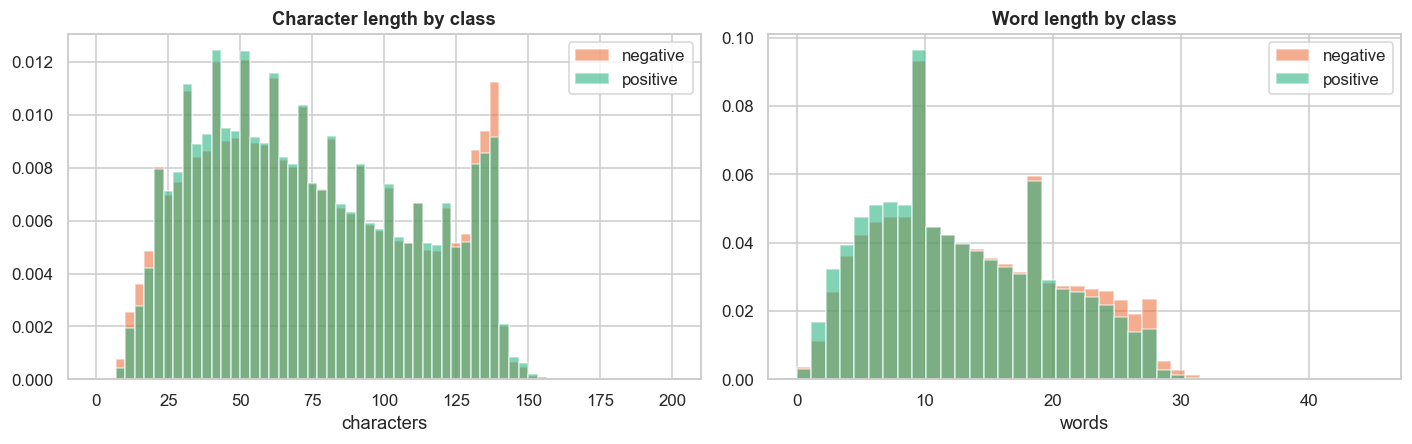

label                  0         1
char_len count  640000.0  640000.0
         mean       74.3      73.9
         std        36.7      36.1
         min         6.0       6.0
         25%        44.0      44.0
         50%        70.0      69.0
         75%       104.0     103.0
         max       359.0     374.0
word_len count  640000.0  640000.0
         mean       13.6      12.8
         std         7.1       6.8
         min         1.0       1.0
         25%         8.0       7.0
         50%        13.0      12.0
         75%        19.0      18.0
         max        57.0      58.0

In [6]:
train["char_len"] = train["text"].str.len()
train["word_len"]  = train["text"].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for c in (0, 1):
    sub = train[train.label == c]
    ax[0].hist(sub["char_len"], bins=60, range=(0, 200), alpha=0.55,
               color=PALETTE[c], label=LAB[c], density=True)
    ax[1].hist(sub["word_len"], bins=40, range=(0, 45), alpha=0.55,
               color=PALETTE[c], label=LAB[c], density=True)
ax[0].set_title("Character length by class"); ax[0].set_xlabel("characters"); ax[0].legend()
ax[1].set_title("Word length by class"); ax[1].set_xlabel("words"); ax[1].legend()
plt.tight_layout(); savefig("02_length"); plt.show()

display(train.groupby("label")[["char_len", "word_len"]]
        .describe().round(1).T)


## 5. Vocabulary & token analysis (§3.3.2)
Vocabulary size, type–token ratio, the Zipfian frequency profile and vocabulary growth characterise the lexical sparsity that motivates (a) sub-word transformer embeddings for the semantic path and (b) TF-IDF/aggregated features rather than raw one-hot tokens for the structural path.

In [7]:
tok_re = re.compile(r"[a-z']+")
def tokenize(s): return tok_re.findall(s.lower())

tokens_per_tweet = samp["clean_text"].map(tokenize)
all_tokens = [t for toks in tokens_per_tweet for t in toks]
vocab = Counter(all_tokens)
print(f"Sample tweets: {len(samp):,}")
print(f"Total tokens : {len(all_tokens):,}")
print(f"Vocabulary   : {len(vocab):,} unique types")
print(f"Type-token ratio (TTR): {len(vocab)/len(all_tokens):.4f}")
print(f"Hapax legomena (freq==1): {sum(1 for v in vocab.values() if v==1):,} "
      f"({sum(1 for v in vocab.values() if v==1)/len(vocab):.1%} of vocab)")


Sample tweets: 150,000
Total tokens : 2,040,337
Vocabulary   : 65,282 unique types
Type-token ratio (TTR): 0.0320
Hapax legomena (freq==1): 37,883 (58.0% of vocab)


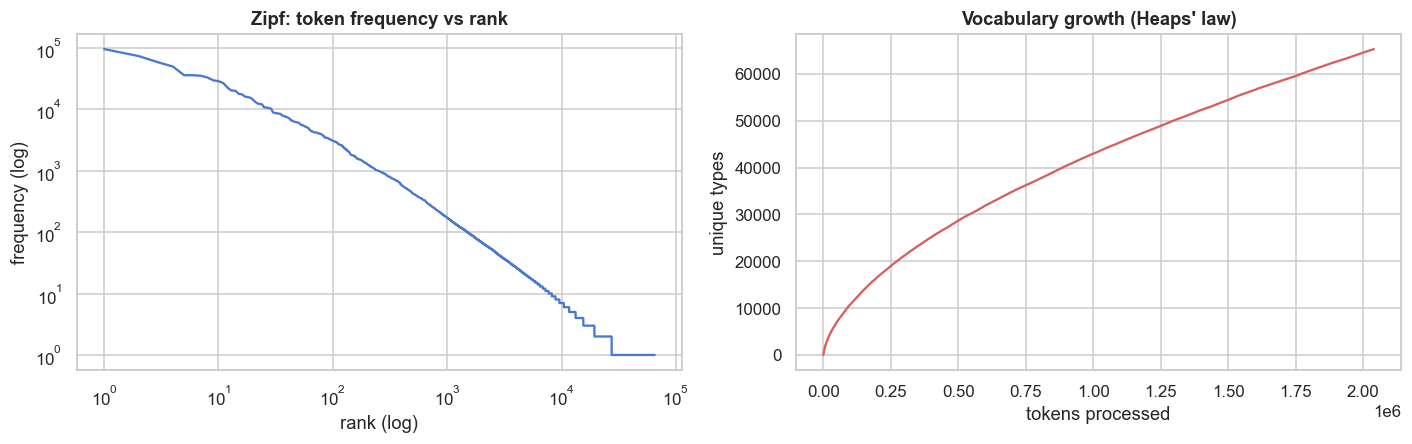

In [8]:
# Zipf plot + vocabulary growth (Heaps' law)
freqs = np.array(sorted(vocab.values(), reverse=True))
ranks = np.arange(1, len(freqs) + 1)
seen, growth_x, growth_y = set(), [], []
step = max(1, len(all_tokens)//300)
for i, t in enumerate(all_tokens):
    seen.add(t)
    if i % step == 0:
        growth_x.append(i); growth_y.append(len(seen))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].loglog(ranks, freqs, color="#4878d0")
ax[0].set_title("Zipf: token frequency vs rank"); ax[0].set_xlabel("rank (log)"); ax[0].set_ylabel("frequency (log)")
ax[1].plot(growth_x, growth_y, color="#d65f5f")
ax[1].set_title("Vocabulary growth (Heaps' law)"); ax[1].set_xlabel("tokens processed"); ax[1].set_ylabel("unique types")
plt.tight_layout(); savefig("03_vocab"); plt.show()


## 6. Word & n-gram frequency (§3.3.3)
Beyond raw frequency we compute **class-distinctive** words via a smoothed log-odds ratio, which is what actually separates sentiment and previews the lexical signal available to both experts.

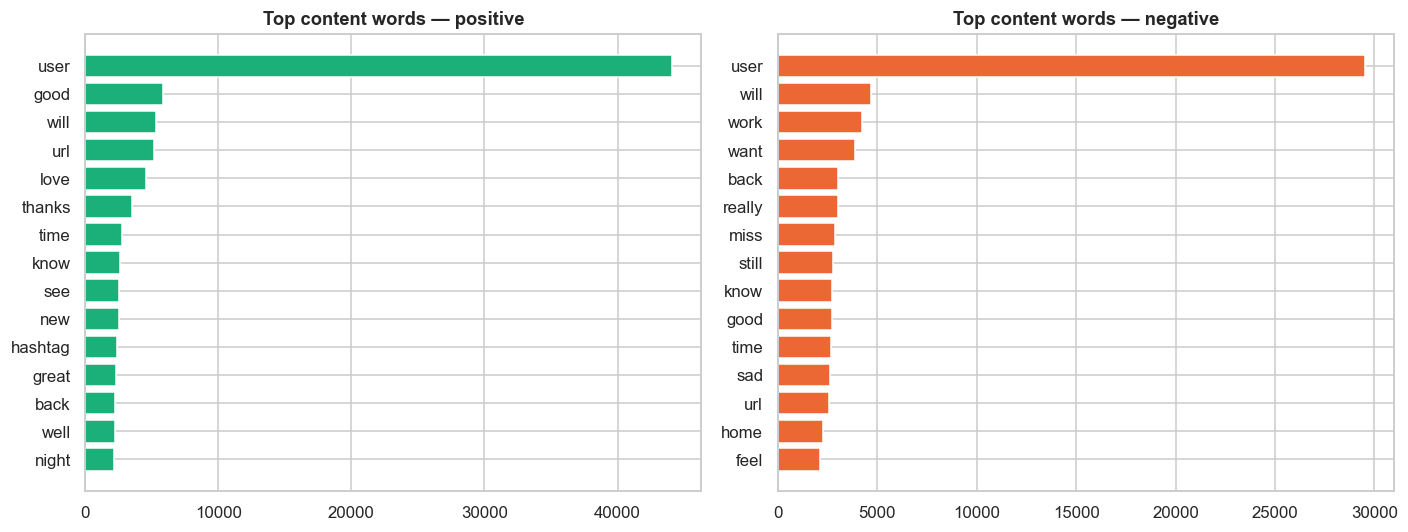

In [9]:
from wordcloud import WordCloud, STOPWORDS
SW = set(STOPWORDS) | {"im","u","2","4","get","got","dont","cant","amp","rt","lol",
                       "quot","go","going","today","day","one","like","just","now"}

def class_counts(label):
    c = Counter()
    for toks in samp.loc[samp.label == label, "clean_text"].map(tokenize):
        c.update(t for t in toks if t not in SW and len(t) > 2)
    return c
pos_c, neg_c = class_counts(1), class_counts(0)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (c, ttl, col) in zip(ax, [(pos_c,"positive","#1baf7a"), (neg_c,"negative","#eb6834")]):
    top = c.most_common(15)[::-1]
    a.barh([w for w,_ in top], [n for _,n in top], color=col)
    a.set_title(f"Top content words — {ttl}")
plt.tight_layout(); savefig("04_topwords"); plt.show()


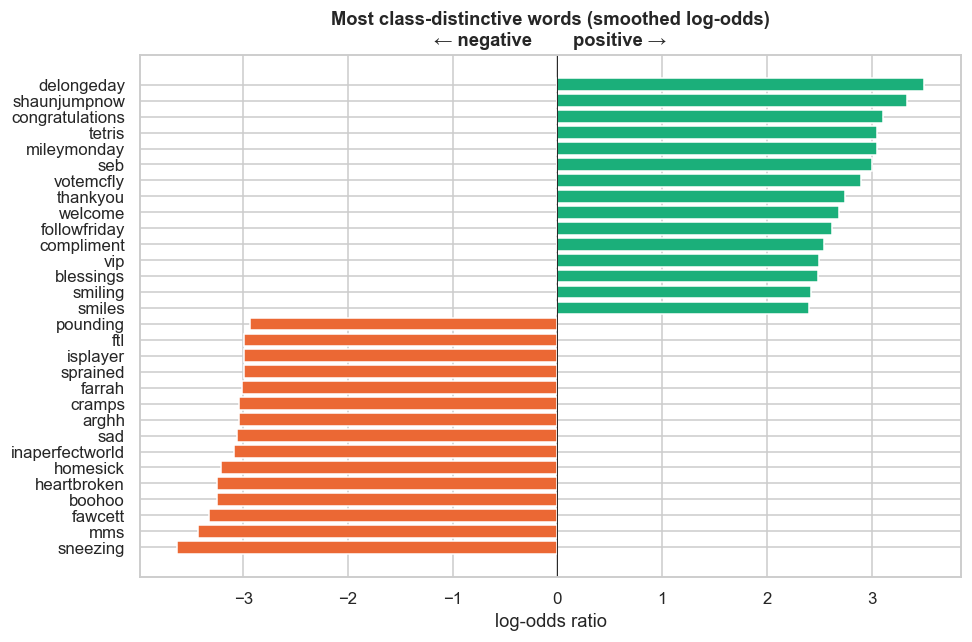

In [10]:
# Smoothed log-odds: which words most distinguish the classes
alpha = 1.0
vocab_all = set(pos_c) | set(neg_c)
Np, Nn = sum(pos_c.values()), sum(neg_c.values())
logodds = {}
for w in vocab_all:
    if pos_c[w] + neg_c[w] < 15:  # ignore very rare words
        continue
    lo = math.log((pos_c[w]+alpha)/(Np+alpha)) - math.log((neg_c[w]+alpha)/(Nn+alpha))
    logodds[w] = lo
ranked = sorted(logodds.items(), key=lambda kv: kv[1])
most_neg = ranked[:15]; most_pos = ranked[-15:]

fig, ax = plt.subplots(figsize=(9, 6))
words = [w for w,_ in most_neg] + [w for w,_ in most_pos]
vals  = [v for _,v in most_neg] + [v for _,v in most_pos]
colors = ["#eb6834"]*len(most_neg) + ["#1baf7a"]*len(most_pos)
order = np.argsort(vals)
ax.barh([words[i] for i in order], [vals[i] for i in order], color=[colors[i] for i in order])
ax.axvline(0, color="k", lw=0.6)
ax.set_title("Most class-distinctive words (smoothed log-odds)\n← negative        positive →")
ax.set_xlabel("log-odds ratio")
plt.tight_layout(); savefig("05_logodds"); plt.show()


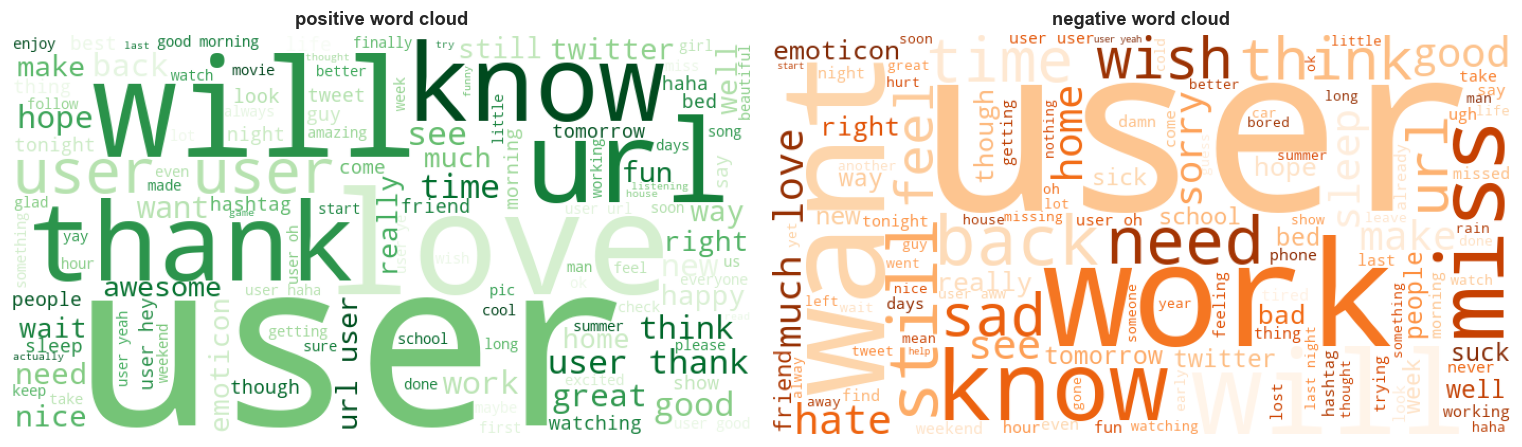

In [11]:
# Word clouds per class
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, (c, ttl) in zip(ax, [(1,"positive"), (0,"negative")]):
    text = " ".join(samp.loc[samp.label == c, "clean_text"])
    wc = WordCloud(width=700, height=380, background_color="white",
                   stopwords=SW, colormap="Greens" if c==1 else "Oranges",
                   max_words=120).generate(text)
    a.imshow(wc); a.axis("off"); a.set_title(f"{ttl} word cloud")
plt.tight_layout(); savefig("06_wordclouds"); plt.show()


## 7. Hashtags & mentions (§3.3.4)
Hashtags and mentions are Twitter-specific structural markers. The corpus already carries `hashtag_count`, `hashtag_sentiment` and hashtag polarity tallies, which feed the structural expert; we profile their prevalence and sentiment association.

Tweets with >=1 hashtag: 2.2%
Tweets with >=1 mention: 46.1%
Tweets with a URL      : 4.6%


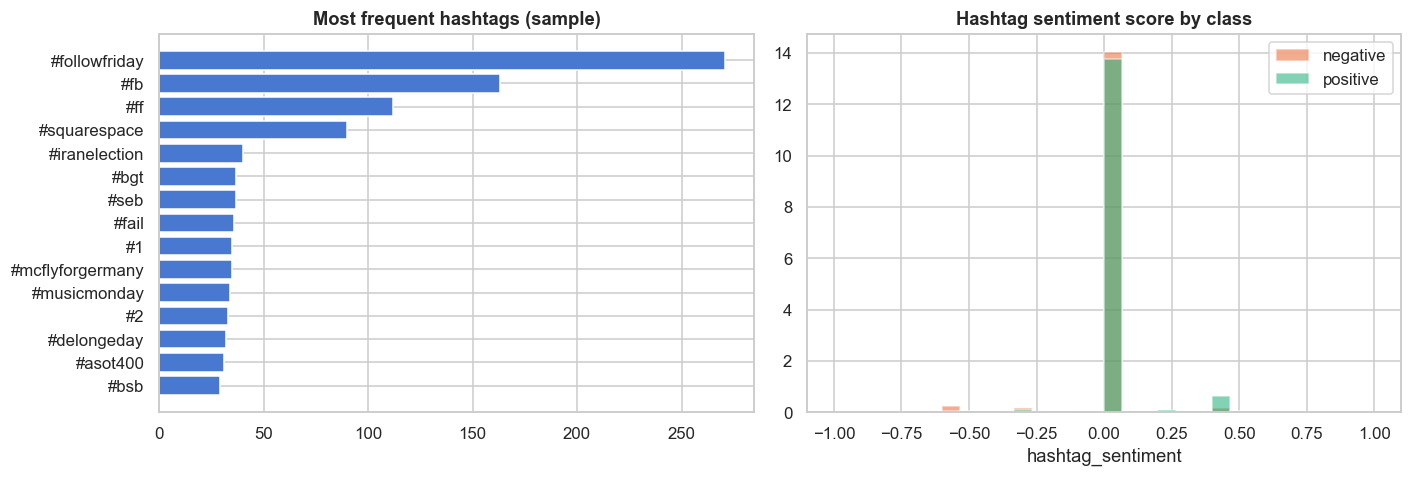

In [12]:
hashtags = samp["text"].str.findall(r"#\w+")
mentions = samp["text"].str.findall(r"@\w+")
urls     = samp["text"].str.contains(r"http\S+|www\.\S+", regex=True)
print(f"Tweets with >=1 hashtag: {(samp['hashtag_count']>0).mean():.1%}")
print(f"Tweets with >=1 mention: {mentions.map(len).gt(0).mean():.1%}")
print(f"Tweets with a URL      : {urls.mean():.1%}")

top_h = Counter(h.lower() for hs in hashtags for h in hs).most_common(15)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh([h for h,_ in top_h], [n for _,n in top_h], color="#4878d0")
ax[0].set_title("Most frequent hashtags (sample)")
# hashtag_sentiment by class (existing engineered column)
for c in (0,1):
    sub = train.loc[(train.label==c) & (train.hashtag_count>0), "hashtag_sentiment"]
    ax[1].hist(sub, bins=30, range=(-1,1), alpha=0.55, density=True,
               color=PALETTE[c], label=LAB[c])
ax[1].set_title("Hashtag sentiment score by class"); ax[1].set_xlabel("hashtag_sentiment"); ax[1].legend()
plt.tight_layout(); savefig("07_hashtags"); plt.show()


## 8. Emoji, emoticon & punctuation (§3.3.5)

This section is **especially important for Sentiment140** because the labels themselves were derived from emoticons. We (a) check how much residual emoticon signal survives in the text, and (b) profile punctuation, capitalisation and elongation — the paralinguistic cues the structural expert is built to exploit.

label,negative,positive
emoticon_count,0.024,0.023
exclaim_count,0.481,0.666
question_count,0.146,0.162
ellipsis_count,0.263,0.211
elongated_word_count,0.103,0.105
allcaps_word_count,0.259,0.272


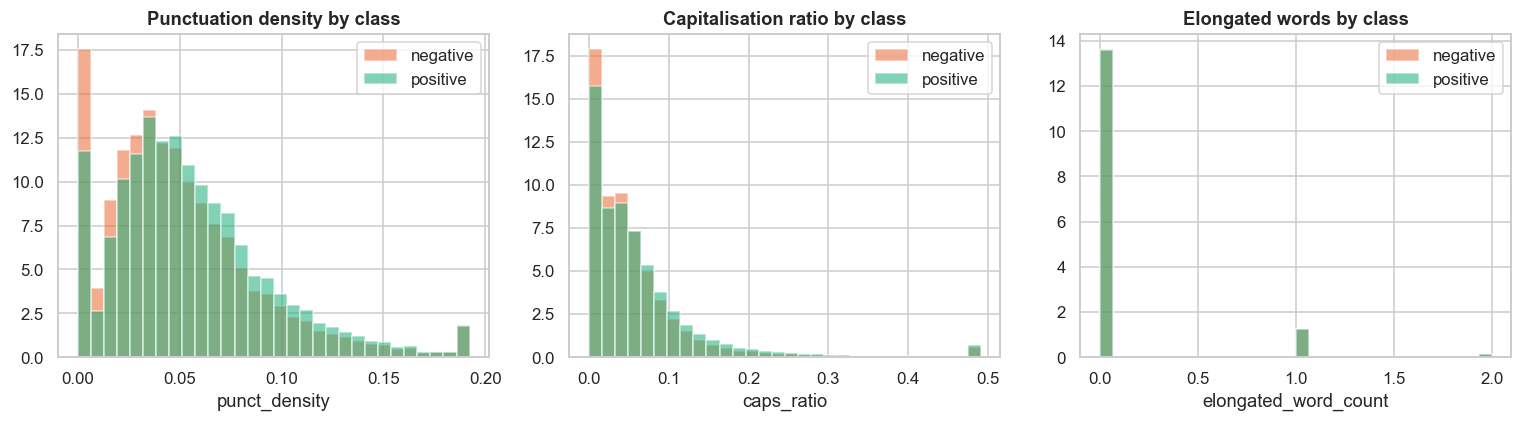

Tweets still containing an emoticon token: 2.2%


In [13]:
# Emoticon presence (distant-supervision signal) and paralinguistic cues by class
cue_cols = ["emoticon_count","exclaim_count","question_count","ellipsis_count",
            "elongated_word_count","allcaps_word_count"]
cue_means = train.groupby("label")[cue_cols].mean().T
display(cue_means.round(3).rename(columns=LAB))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, col, ttl in zip(ax, ["punct_density","caps_ratio","elongated_word_count"],
                       ["Punctuation density","Capitalisation ratio","Elongated words"]):
    for c in (0,1):
        vals = train.loc[train.label==c, col].clip(upper=train[col].quantile(0.99))
        a.hist(vals, bins=30, alpha=0.55, density=True, color=PALETTE[c], label=LAB[c])
    a.set_title(f"{ttl} by class"); a.set_xlabel(col); a.legend()
plt.tight_layout(); savefig("08_paralinguistic"); plt.show()
print(f"Tweets still containing an emoticon token: {(train['emoticon_count']>0).mean():.1%}")


In [14]:
# Top emojis per class (if any survive) using the emot library
try:
    from emot.core import emot as _Emot
    E = _Emot()                      # instantiate ONCE (re-instantiating per call is very slow)
    def emojis(s):
        try: return E.emoji(s).get("value", [])
        except Exception: return []
    pos_e, neg_e = Counter(), Counter()
    for t in samp.loc[samp.label==1,"text"].head(5000): pos_e.update(emojis(t))
    for t in samp.loc[samp.label==0,"text"].head(5000): neg_e.update(emojis(t))
    print("Top positive-class emojis:", pos_e.most_common(10))
    print("Top negative-class emojis:", neg_e.most_common(10))
    if not pos_e and not neg_e:
        print("(No unicode emoji found — 2009 tweets predate widespread emoji; sentiment came via ASCII emoticons.)")
except Exception as e:
    print("emoji scan skipped:", e)


Top positive-class emojis: [('©', 1)]
Top negative-class emojis: [('©', 3)]


## 9. Structural-feature analysis — the structural channel

The corpus ships the full engineered feature set used by the XGBoost expert. We (a) rank every feature by its **point-biserial correlation** with the label (which structural signals actually carry sentiment), (b) show the correlation structure among features, and (c) contrast class distributions for the strongest ones.

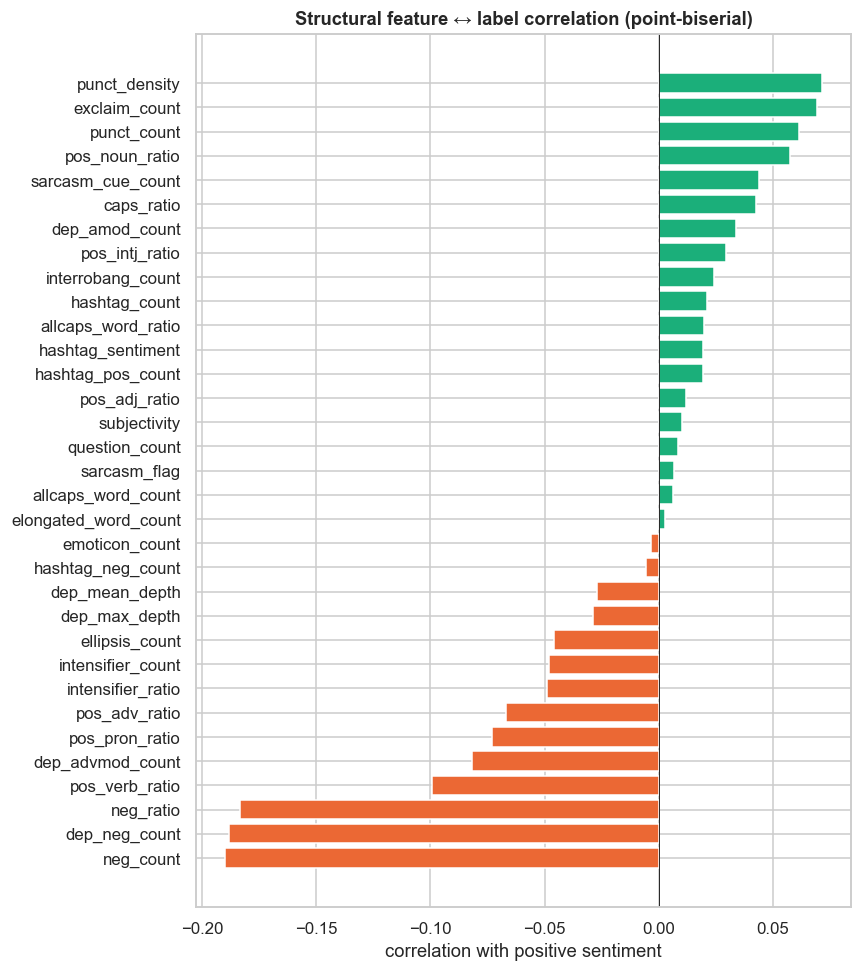

Strongest positive: {'sarcasm_cue_count': 0.044, 'pos_noun_ratio': 0.057, 'punct_count': 0.061, 'exclaim_count': 0.069, 'punct_density': 0.071}
Strongest negative: {'neg_count': -0.19, 'dep_neg_count': -0.188, 'neg_ratio': -0.184, 'pos_verb_ratio': -0.099, 'dep_advmod_count': -0.082}


In [15]:
# Point-biserial correlation of each structural feature with the label
corr = {c: np.corrcoef(train[c].fillna(0), train["label"])[0,1] for c in STRUCT}
corr = pd.Series(corr).sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
colors = ["#1baf7a" if v>0 else "#eb6834" for v in corr.values]
ax.barh(corr.index, corr.values, color=colors); ax.axvline(0, color="k", lw=0.6)
ax.set_title("Structural feature ↔ label correlation (point-biserial)")
ax.set_xlabel("correlation with positive sentiment")
plt.tight_layout(); savefig("09_feature_corr"); plt.show()
print("Strongest positive:", corr.tail(5).round(3).to_dict())
print("Strongest negative:", corr.head(5).round(3).to_dict())


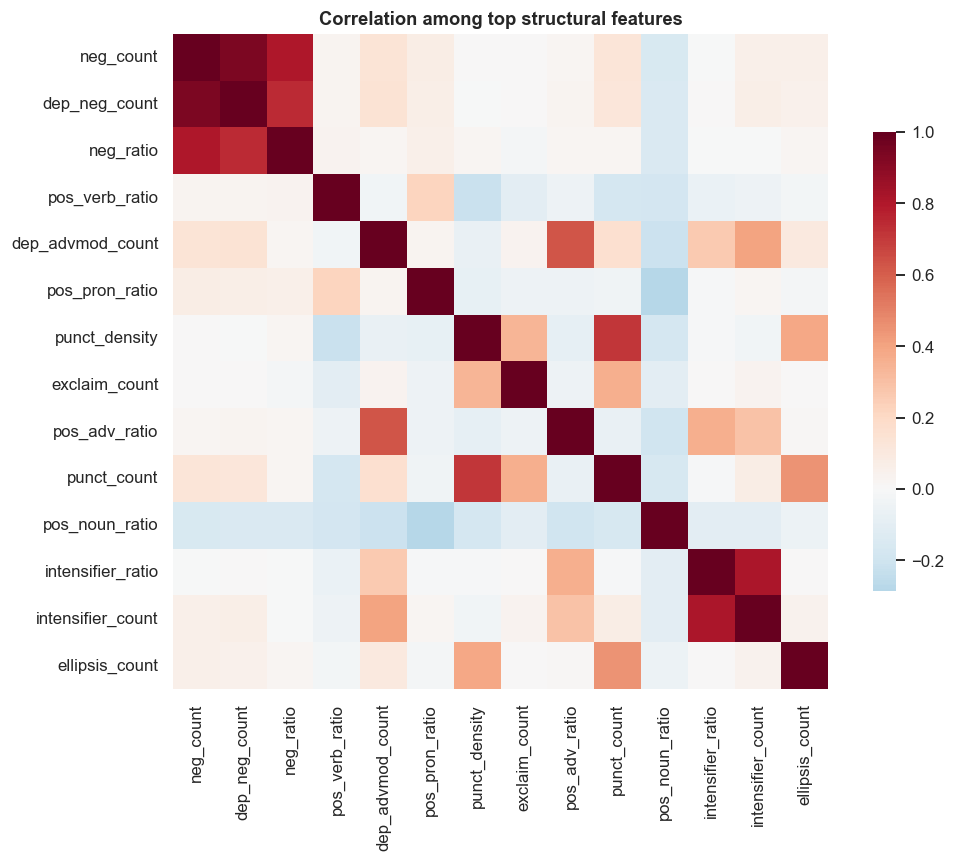

In [16]:
# Correlation heatmap among the most informative structural features
top_feats = corr.abs().sort_values(ascending=False).head(14).index.tolist()
cmat = train[top_feats].fillna(0).corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cmat, cmap="RdBu_r", center=0, annot=False, square=True, ax=ax,
            cbar_kws={"shrink":0.7})
ax.set_title("Correlation among top structural features")
plt.tight_layout(); savefig("10_feature_heatmap"); plt.show()


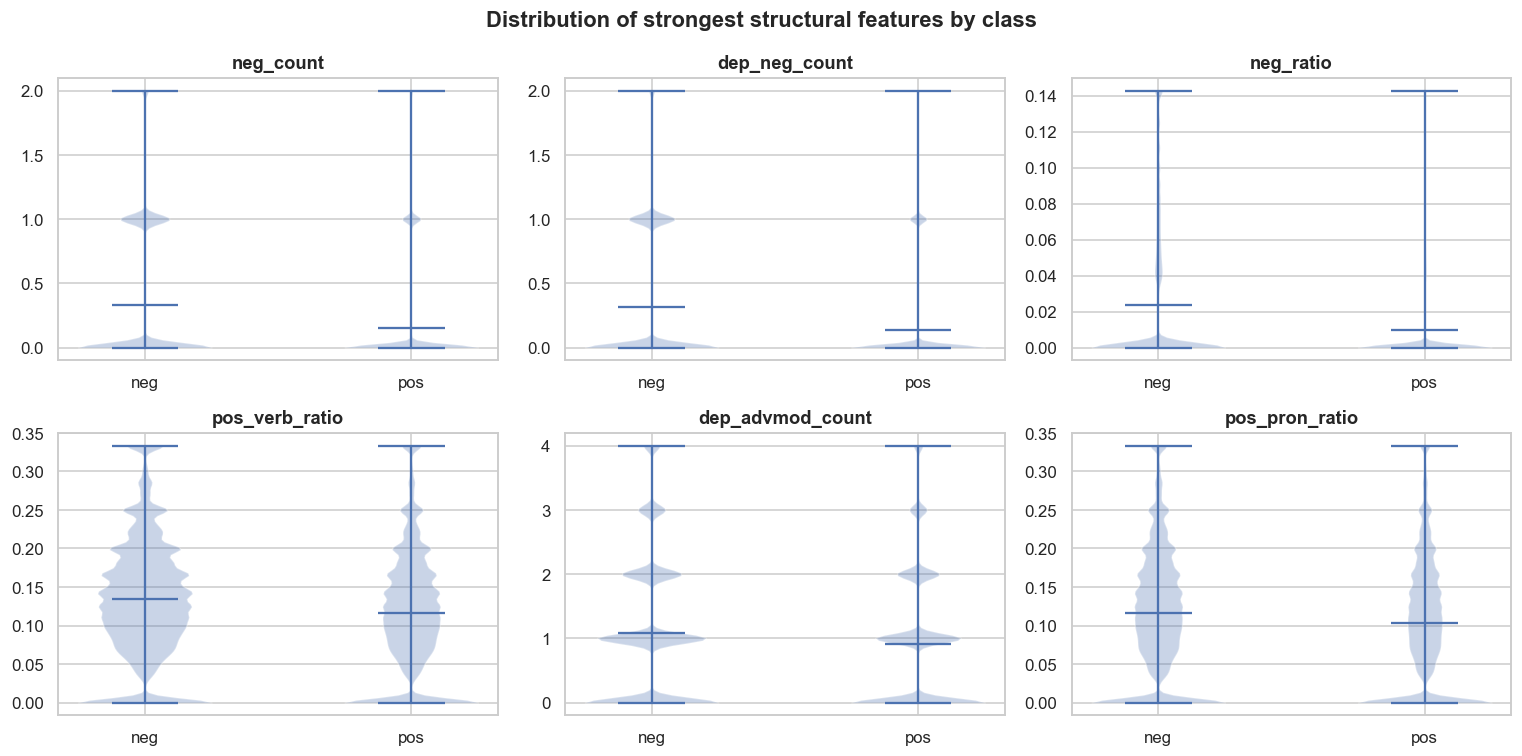

In [17]:
# Class distributions for the six strongest structural features
strong = corr.abs().sort_values(ascending=False).head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, col in zip(axes.ravel(), strong):
    data = [train.loc[train.label==c, col].clip(upper=train[col].quantile(0.98)) for c in (0,1)]
    parts = a.violinplot(data, showmeans=True)
    a.set_xticks([1,2]); a.set_xticklabels(["neg","pos"]); a.set_title(col)
plt.suptitle("Distribution of strongest structural features by class", fontweight="bold")
plt.tight_layout(); savefig("11_struct_violins"); plt.show()


## 10. Structural-only separability — motivating the dual path

A quick logistic regression on the engineered features alone estimates how much sentiment the **structural channel** can recover. A moderate-but-limited accuracy is exactly the motivation for adding a semantic expert: the structural signal is real, yet leaves a large gap that only contextual meaning can close.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
Xs = StandardScaler().fit_transform(train[STRUCT].fillna(0).values)
ys = train["label"].values
n = min(200_000, len(Xs)); idx = np.random.RandomState(SEED).permutation(len(Xs))[:n]
cut = int(0.8*n)
clf = LogisticRegression(max_iter=500).fit(Xs[idx[:cut]], ys[idx[:cut]])
acc = clf.score(Xs[idx[cut:]], ys[idx[cut:]])
print(f"Structural-only logistic-regression accuracy (held-out): {acc:.4f}")
print("Interpretation: the structural channel alone recovers a moderate share of sentiment,")
print("leaving substantial headroom that the semantic (KAN) expert is designed to capture.")


Structural-only logistic-regression accuracy (held-out): 0.6136
Interpretation: the structural channel alone recovers a moderate share of sentiment,
leaving substantial headroom that the semantic (KAN) expert is designed to capture.


## 11. Label quality & distant-supervision noise

Because labels come from emoticons, some are wrong. We estimate a **lower bound** on label noise by finding tweets whose lexical sentiment strongly contradicts the assigned label, and we report the sarcasm-cue rate — a known driver of emoticon-mislabelling. This quantifies the accuracy ceiling discussed in the methodology.

In [19]:
# VADER lexical polarity vs assigned label (contradiction = likely noise/sarcasm)
try:
    import nltk
    from nltk.sentiment import SentimentIntensityAnalyzer
    try: sia = SentimentIntensityAnalyzer()
    except Exception:
        nltk.download("vader_lexicon", quiet=True); sia = SentimentIntensityAnalyzer()
    s2 = samp.head(40000).copy()
    s2["vader"] = s2["text"].map(lambda t: sia.polarity_scores(t)["compound"])
    contra = ((s2.label==1)&(s2.vader<=-0.5)) | ((s2.label==0)&(s2.vader>=0.5))
    print(f"Strong lexical–label contradictions: {contra.mean():.1%} of tweets "
          f"(a lower bound on distant-supervision label noise)")
    print(f"Tweets with a surface sarcasm cue: {(train['sarcasm_cue_count']>0).mean():.1%}  "
          f"(strict sarcasm_flag fires on only {(train['sarcasm_flag']==1).mean():.2%} — surface "
          f"heuristics badly under-detect sarcasm, an argument for contextual modelling)")
    print("\nExamples of likely-mislabelled tweets (label vs lexical polarity):")
    for _, r in s2[contra].head(6).iterrows():
        print(f"  label={LAB[r.label]:8} vader={r.vader:+.2f}  \"{r.text[:90]}\"")
except Exception as e:
    print("VADER contradiction analysis skipped:", e)


Strong lexical–label contradictions: 8.4% of tweets (a lower bound on distant-supervision label noise)
Tweets with a surface sarcasm cue: 1.7%  (strict sarcasm_flag fires on only 0.03% — surface heuristics badly under-detect sarcasm, an argument for contextual modelling)

Examples of likely-mislabelled tweets (label vs lexical polarity):
  label=negative vader=+0.51  "Baby birdy fell out of a tree today during math. Tried to put it back in its nest and fell"
  label=negative vader=+0.74  "&quot;do not pity the dead. pity the living, and, above all, those who live without love.&"
  label=negative vader=+0.93  "i just love post-game traffic. but it's worth it, because the #mets won, 3-2. citi field i"
  label=negative vader=+0.90  "@GraceDePol haha lol or a carrier bag ... haha lol x i have nothing left since i paid for "
  label=positive vader=-0.66  "If you get an email from the NHS telling you not to eat tinned pork because of swine flu i"
  label=negative vader=+0.74  "The sky is fal

## 12. Negation & sarcasm deep-dive — motivating the semantic KAN

Negation and sarcasm invert surface sentiment in ways that bag-of-features models struggle with; they are the clearest argument for a **contextual** semantic expert. We report their prevalence and show examples where structural cues alone would mislead.

In [20]:
print(f"Tweets containing negation (neg_count>0):      {(train['neg_count']>0).mean():.1%}")
print(f"Tweets with a dependency-parsed negation:      {(train['dep_neg_count']>0).mean():.1%}")
print(f"Tweets with a surface sarcasm cue (cue>0):     {(train['sarcasm_cue_count']>0).mean():.1%}")
print(f"Strict sarcasm_flag rate:                      {(train['sarcasm_flag']==1).mean():.2%}  "
      f"(heuristics rarely fire ⇒ sarcasm is largely invisible to surface features)")

# negation rate does not trivially predict class -> needs context
neg_by_class = train.groupby("label")["neg_count"].apply(lambda s: (s>0).mean())
print("\nNegation prevalence by class:", {LAB[k]: round(v,3) for k,v in neg_by_class.items()})
print("\nExample negated tweets (surface words != meaning):")
for t in train.loc[train.neg_count>=2, "text"].head(6):
    print("  •", t[:100])


Tweets containing negation (neg_count>0):      21.8%
Tweets with a dependency-parsed negation:      20.5%
Tweets with a surface sarcasm cue (cue>0):     1.7%
Strict sarcasm_flag rate:                      0.03%  (heuristics rarely fire ⇒ sarcasm is largely invisible to surface features)

Negation prevalence by class: {'negative': 0.299, 'positive': 0.136}

Example negated tweets (surface words != meaning):
  • I won't block you, but just remember you can't tweet me 
  • I don't have internet on my phone anymore so i don't think i can use twitpic anymore 
  • @acapublicist nope not even close!  hope ur cool luvy! xcx
  • Why aren't we like we used to be? I hate not knowing what we'll end up happening. Drift Away 
  • @JeepersMedia I'm watching your blogtv, but I can't say anything cause I'm not added as a friend 
  • @jennwagner no they can't...i have tried to send replies to someone i followed but didn't follow me,


## 13. Findings & modelling implications (§3.3.6)

**Dataset shape & balance.** ~1.28M/160k/160k stratified splits, ~50/50 classes ⇒ accuracy is a fair headline metric; no re-balancing needed for the semantic path (XGBoost still uses `scale_pos_weight` defensively).

**Length & sparsity.** Tweets are short (mostly < 30 words) with a heavy Zipfian tail and many hapax legomena ⇒ (i) a modest embedding max-token length suffices; (ii) sub-word transformer embeddings and *aggregated* structural features are preferable to raw one-hot tokens for the structural path.

**Structural channel is real but limited.** Several engineered features correlate with sentiment (subjectivity, punctuation/caps intensity, hashtag sentiment, negation, POS ratios), and a structural-only linear model recovers a **moderate** accuracy — but well below the semantic ceiling. This is the empirical basis for the dual-path design: keep an interpretable structural expert, but pair it with a stronger semantic one.

**Semantic channel is necessary.** Negation appears in ~22% of tweets, and — tellingly — surface sarcasm heuristics fire on only ~1.7% of tweets while true sarcasm is far more common, so sarcasm is *largely invisible to structural features*. Both phenomena invert surface sentiment and demand contextual modelling, which is precisely the semantic KAN's role and why sarcasm emerges as a non-monotonic concept in the KAN analysis.

**Distant-supervision noise ⇒ a real ceiling.** A measurable fraction of tweets carry lexical sentiment contradicting their emoticon-derived label. This label noise caps attainable accuracy (~0.87 for strong single models), and the study reports results against that ceiling rather than pretending it away.

**Preprocessing implications.** Because casing, punctuation, elongation, emoji and hashtags are sentiment-bearing, the pipeline preserves them for the structural path and applies only light, sentiment-preserving normalisation for the semantic path — a *dual* preprocessing pipeline rather than one shared aggressive clean.

**Fusion implication.** The structural and semantic channels succeed and fail on *different* tweets (different feature correlations, negation/sarcasm handling), so a per-sample adaptive gate that reasons about confidence and disagreement is the appropriate way to combine them.
